# Umbral mixto: Deep Ensemble detecta, Neural Process corrige

**Idea.** Usar la probabilidad del Deep Ensemble para decidir dónde hay un huso y la duda de Neural Process (su MI) para corregir sus errores: borrar detecciones dudosas (falsos positivos) y recuperar husos que se le pasaron (falsos negativos).

**Datos.** Evaluaciones 0, 1 y 2, cinco folds cada una (15 folds). Se leen los `validation_predictions.npz` y `test_predictions.npz` ya guardados: no se entrena ni se vuelve a inferir. En cada fold, todo umbral o modelo se elige con **validación** y se prueba **una sola vez** en **test**. El código está en `src/eeg_uq/hybrid_threshold.py`.

**Pasos**

1. **Punto de partida justo**: ajustar el umbral de probabilidad sin incertidumbre.
2. **Lista de eventos**: las detecciones del Deep Ensemble y los tramos *casi detectados* (probabilidad ≥ 0.25 que no llegaron a detección), con sus medidas de los dos métodos.
3. **¿Vale la pena mezclar?** ¿La MI de Neural Process dice algo que la probabilidad del Deep Ensemble no dice ya?
4. **Tres reglas**: (1) cortes fijos, (2) umbral que baja donde Neural Process duda, (3) regresión logística por evento.
5. **Resultado en test** con la F1 oficial (IoU ≥ 0.2, el mismo emparejamiento del notebook original).

**Regla de F1.** Con F1 ≈ 83%, borrar una detección sube el F1 solo si más del ~58% de lo borrado es FP; agregar un tramo lo sube solo si más del ~42% de lo agregado es huso real (F1/2).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import hybrid_threshold as ht
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

REFRESH = False  # True recalcula desde los NPZ (~3 minutos)
results = ht.run_all(refresh=REFRESH)
scores, separation, counts, events, params = (results[k] for k in ('scores', 'separation', 'counts', 'events', 'params'))

## 1. Punto de partida: ajustar el umbral sin incertidumbre

El postprocesado (`process_spindle_simple`) **solo usa el umbral de duración** (0.425): la máscara del umbral de detección (0.5) se recibe pero no se usa. Por eso se ajusta un solo número, en una grilla de 0.25 a 0.65 elegida con la F1 de validación.

In [2]:
baselines = results['baselines']
for method in ['SEED', 'Deep Ensemble', 'Neural Process']:
    print(method)
    display(report.by_evaluation(baselines[baselines['método'] == method],
                                 ['umbral elegido', 'F1 (%) original', 'F1 (%) ajustado', 'precisión (%) original',
                                  'precisión (%) ajustado', 'recall (%) original', 'recall (%) ajustado']))

SEED


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
umbral elegido,0.45 ± 0.12,0.36 ± 0.11,0.485 ± 0.055,0.4317 ± 0.11
F1 (%) original,82.39 ± 0.66,82.93 ± 0.88,82.83 ± 0.86,82.72 ± 0.79
F1 (%) ajustado,82.7 ± 1.3,83.28 ± 0.57,82.67 ± 1.1,82.88 ± 1
precisión (%) original,83.5 ± 6.3,84.62 ± 2.9,82.41 ± 3.5,83.51 ± 4.3
precisión (%) ajustado,84.06 ± 3.9,82.78 ± 2,83.97 ± 3.1,83.6 ± 2.9
recall (%) original,82.08 ± 6.5,81.46 ± 3.1,83.44 ± 2.8,82.33 ± 4.2
recall (%) ajustado,81.74 ± 5.1,83.86 ± 1.9,81.65 ± 4.2,82.42 ± 3.8


Deep Ensemble


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
umbral elegido,0.41 ± 0.074,0.39 ± 0.058,0.395 ± 0.074,0.3983 ± 0.064
F1 (%) original,83.55 ± 0.91,83.79 ± 0.41,83.35 ± 1.2,83.57 ± 0.85
F1 (%) ajustado,83.44 ± 1.1,83.82 ± 0.31,83.51 ± 0.85,83.59 ± 0.77
precisión (%) original,84.22 ± 4.3,84.42 ± 2.2,84.5 ± 3.7,84.38 ± 3.3
precisión (%) ajustado,83.63 ± 5.7,83.42 ± 2.4,83.61 ± 2.6,83.55 ± 3.6
recall (%) original,83.24 ± 4.5,83.25 ± 2.1,82.44 ± 3.2,82.98 ± 3.2
recall (%) ajustado,83.8 ± 5.4,84.32 ± 2.3,83.56 ± 2.9,83.89 ± 3.5


Neural Process


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
umbral elegido,0.435 ± 0.1,0.395 ± 0.097,0.395 ± 0.11,0.4083 ± 0.097
F1 (%) original,83.43 ± 0.89,83.29 ± 0.72,83.32 ± 1.3,83.34 ± 0.92
F1 (%) ajustado,83 ± 0.82,83.07 ± 0.63,83.35 ± 1.2,83.14 ± 0.86
precisión (%) original,84.58 ± 3.6,84.73 ± 2.5,86.18 ± 2.3,85.16 ± 2.7
precisión (%) ajustado,84.18 ± 5,84.31 ± 2.6,85.23 ± 0.48,84.57 ± 3.1
recall (%) original,82.49 ± 3.1,81.98 ± 1.9,80.75 ± 3.2,81.74 ± 2.7
recall (%) ajustado,82.29 ± 4.8,82 ± 2.6,81.6 ± 2.6,81.96 ± 3.3


## 2. Lista de eventos

Por fold de test: cuántas detecciones y cuántos *casi detectados* hay, qué parte de los casi detectados es un huso real, y qué parte de los husos perdidos (FN) está entre ellos (el resto tiene probabilidad < 0.25 y ninguna regla de este notebook puede recuperarlos).

In [3]:
display(report.by_evaluation(counts[counts['base'] == 'original 0.425'],
                             ['detecciones (test)', 'casi detectados (test)', '% reales en casi detectados',
                              '% de los FN que están en casi detectados']))

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
detecciones (test),1059 ± 1e+02,1055 ± 71,1047 ± 1.3e+02,1054 ± 96
casi detectados (test),184.8 ± 34,185.2 ± 31,174.4 ± 21,181.5 ± 28
% reales en casi detectados,35.03 ± 11,33.62 ± 3.3,35.85 ± 10,34.83 ± 8.3
% de los FN que están en casi detectados,35.28 ± 3.6,35.02 ± 6.4,32.49 ± 3,34.26 ± 4.4


## 3. ¿Vale la pena mezclar?

AUROC en test para encontrar el error de cada grupo: en las **detecciones**, los FP; en los **casi detectados**, los husos reales. La logística se entrena en validación con las medidas del Deep Ensemble solo, o con las del Deep Ensemble más las de Neural Process. *ρ* es la correlación de Spearman entre la MI de los dos métodos en los mismos eventos.

Criterio fijado antes de mirar el test: si agregar Neural Process no sube el AUROC al menos ~0.02, la mezcla no vale la pena.

In [4]:
SEPARATION = ['eventos', 'positivos', 'azar AUPRC', 'ρ Spearman MI DE vs MI NP', 'AUROC p media DE', 'AUROC MI DE', 'AUROC MI NP',
              'AUROC logística solo DE', 'AUROC logística DE + NP', 'AUPRC logística solo DE', 'AUPRC logística DE + NP']
base_sep = separation[separation['base'] == 'original 0.425']
for group in ['detecciones: TP vs FP', 'casi detectados: huso real vs no']:
    print(group)
    display(report.by_evaluation(base_sep[base_sep['grupo'] == group], SEPARATION))

detecciones: TP vs FP


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
eventos,1059 ± 1e+02,1055 ± 71,1047 ± 1.3e+02,1054 ± 96
positivos,170.4 ± 58,165.4 ± 33,165.6 ± 60,167.1 ± 48
azar AUPRC,0.1578 ± 0.043,0.1559 ± 0.022,0.1553 ± 0.037,0.1564 ± 0.033
ρ Spearman MI DE vs MI NP,0.7084 ± 0.088,0.7701 ± 0.042,0.7079 ± 0.025,0.7288 ± 0.062
AUROC p media DE,0.8601 ± 0.015,0.8567 ± 0.01,0.8596 ± 0.017,0.8588 ± 0.013
AUROC MI DE,0.7775 ± 0.014,0.789 ± 0.0088,0.7863 ± 0.015,0.7843 ± 0.013
AUROC MI NP,0.8194 ± 0.032,0.8254 ± 0.019,0.8298 ± 0.022,0.8249 ± 0.023
AUROC logística solo DE,0.8591 ± 0.013,0.8532 ± 0.014,0.8637 ± 0.013,0.8587 ± 0.013
AUROC logística DE + NP,0.8599 ± 0.014,0.8574 ± 0.014,0.8651 ± 0.014,0.8608 ± 0.013
AUPRC logística solo DE,0.4679 ± 0.1,0.4801 ± 0.031,0.4787 ± 0.095,0.4756 ± 0.076


casi detectados: huso real vs no


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
eventos,184.8 ± 34,185.2 ± 31,174.4 ± 21,181.5 ± 28
positivos,62.4 ± 14,61.6 ± 6,61 ± 13,61.67 ± 11
azar AUPRC,0.3503 ± 0.11,0.3362 ± 0.033,0.3585 ± 0.1,0.3483 ± 0.083
ρ Spearman MI DE vs MI NP,-0.1234 ± 0.084,-0.1898 ± 0.089,-0.03911 ± 0.12,-0.1174 ± 0.11
AUROC p media DE,0.5423 ± 0.052,0.5419 ± 0.016,0.5353 ± 0.05,0.5398 ± 0.04
AUROC MI DE,0.5205 ± 0.028,0.4856 ± 0.046,0.474 ± 0.035,0.4933 ± 0.04
AUROC MI NP,0.5448 ± 0.056,0.5439 ± 0.051,0.5503 ± 0.044,0.5464 ± 0.047
AUROC logística solo DE,0.5501 ± 0.055,0.5271 ± 0.025,0.5245 ± 0.041,0.5339 ± 0.041
AUROC logística DE + NP,0.5474 ± 0.058,0.5174 ± 0.029,0.5374 ± 0.051,0.534 ± 0.046
AUPRC logística solo DE,0.4137 ± 0.14,0.3697 ± 0.041,0.3976 ± 0.11,0.3937 ± 0.098


### Gráficos de cajón: MI de Neural Process por tipo de evento

Percentil de la MI dentro del fold (0 = la menor, 1 = la mayor) en los eventos de test. Izquierda: detecciones (TP vs FP). Derecha: casi detectados (huso real vs no). La línea punteada en 0.5 es el azar; la roja, la media.

Comparar con el gráfico de los notebooks 06 y 07: allí los FN se miden en el **tramo real** del huso, que el modelo no conoce al predecir. Aquí se mide en el tramo que el modelo sí ve.

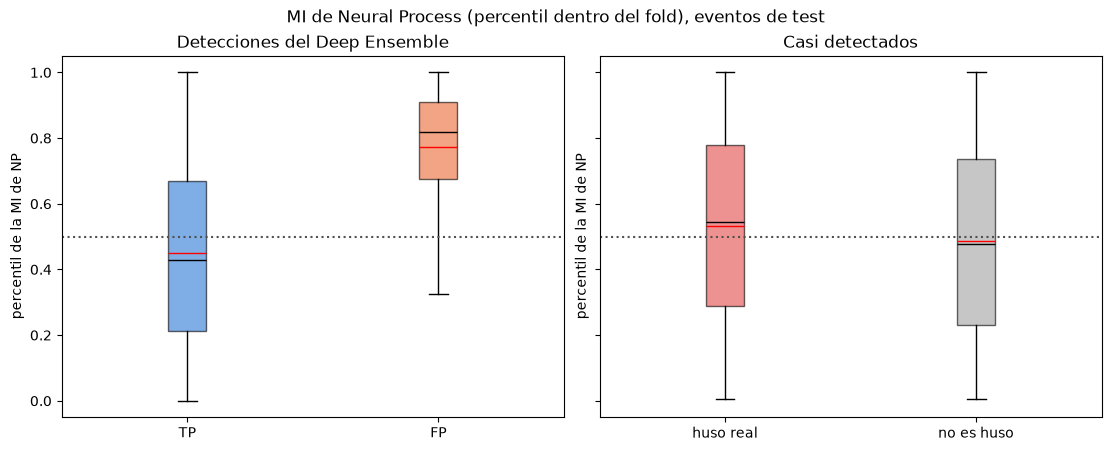

In [5]:
ev = events[events['base'] == 'original 0.425'].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, constrained_layout=True)
fig.suptitle('MI de Neural Process (percentil dentro del fold), eventos de test')
panels = [
    (axes[0], ev[ev['candidato'] == 0], {1: 'TP', 0: 'FP'}, ['#2a78d6', '#eb6834'], 'Detecciones del Deep Ensemble'),
    (axes[1], ev[ev['candidato'] == 1], {1: 'huso real', 0: 'no es huso'}, ['#e34948', '#a0a0a0'], 'Casi detectados'),
]
for ax, part, names, colors, title in panels:
    part = part.assign(percentil=part.groupby(['evaluación', 'fold'])['MI NP'].rank(pct=True))
    values = [part.loc[part['real'] == k, 'percentil'] for k in names]
    box = ax.boxplot(values, tick_labels=list(names.values()), patch_artist=True, showfliers=False,
                     medianprops={'color': 'black'}, showmeans=True, meanline=True, meanprops={'color': 'red', 'linestyle': '-'})
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.axhline(0.5, color=report.CHANCE, linestyle=':')
    ax.set_title(title)
    ax.set_ylabel('percentil de la MI de NP')
show(fig)

## 4 y 5. Reglas y resultado en test

Cada regla se aplica sobre dos bases del Deep Ensemble: el umbral **original** (0.425) y el **ajustado en validación** (paso 1). La versión *(precisión ≥ base)* elige los cortes con la condición de que la precisión de validación no baje de la del Deep Ensemble.

- **Regla 1, cortes fijos**: borrar una detección si su probabilidad < t_p **y** la MI de NP > τ_FP; agregar un casi detectado si la MI de NP > τ_FN.
- **Regla 2, umbral adaptativo**: p ≥ umbral − β · percentil(MI de NP), por timestep, seguido del postprocesado normal.
- **Regla 3, logística**: un modelo para las detecciones y otro para los casi detectados (la MI significa cosas opuestas en cada grupo), cada uno con su corte de probabilidad elegido en validación.

Δ es la diferencia **pareada** por fold contra el Deep Ensemble de la misma base; *p Wilcoxon* compara esas 15 diferencias con cero.

In [6]:
display(ht.summary(scores))

F1 (%) precisión (%)    recall (%)     FP     FN  Δ F1 (puntos)  Δ precisión (puntos) folds que mejoran F1  p Wilcoxon
base                   regla                                                                                                                                                                      
original 0.425         Deep Ensemble                                  83.57 ± 0.85  84.38 ± 3.25  82.98 ± 3.18  166.9  181.8           0.00                  0.00                 0/15         NaN
                       Regla 1: cortes fijos                          83.47 ± 0.94  84.34 ± 3.01  82.81 ± 3.14  166.7  183.5          -0.09                 -0.04                 5/15      0.2213
                       Regla 1: cortes fijos (precisión ≥ base)       83.49 ± 0.94  85.04 ± 3.02  82.18 ± 3.07  156.9  190.2          -0.07                  0.66                 3/15      0.2135
                       Regla 2: umbral adaptativo                     83.52 ± 0.71  82.81 ± 3.25  84.48 ± 3.26  190.0  166.0          -0.04                 -1.57                 5/15      0.8785
                       Regla 2: umbral adaptativo (precisión ≥ base)  83.57 ± 0.85  84.38 ± 3.25  82.98 ± 3.18  166.9  181.8           0.00                  0.00                 0/15         NaN
                       Regla 3: logística solo DE                     83.44 ± 0.94  84.17 ± 3.55  82.99 ± 3.68  169.9  181.8          -0.12                 -0.21                 7/15      0.1354
                       Regla 3: logística solo DE (precisión ≥ base)  83.42 ± 0.88  84.93 ± 3.40  82.21 ± 3.58  158.9  190.0          -0.14                  0.55                 4/15      0.0219
                       Regla 3: logística DE + NP                     83.28 ± 1.01  83.76 ± 4.31  83.19 ± 4.39  177.2  179.7          -0.29                 -0.62                 5/15      0.0151
                       Regla 3: logística DE + NP (precisión ≥ base)  83.43 ± 0.92  84.91 ± 3.59  82.28 ± 3.86  159.6  189.3          -0.13                  0.53                 7/15      0.1514
ajustado en validación Deep Ensemble                                  83.59 ± 0.77  83.55 ± 3.58  83.89 ± 3.51  179.7  172.3           0.00                  0.00                 0/15         NaN
                       Regla 1: cortes fijos                          83.39 ± 0.82  83.34 ± 3.59  83.73 ± 3.77  182.3  174.0          -0.20                 -0.22                 2/15      0.0218
                       Regla 1: cortes fijos (precisión ≥ base)       83.44 ± 0.81  83.69 ± 3.48  83.47 ± 3.76  177.0  176.8          -0.15                  0.13                 2/15      0.1282
                       Regla 2: umbral adaptativo                     83.59 ± 0.77  83.55 ± 3.58  83.89 ± 3.51  179.7  172.3           0.00                  0.00                 0/15         NaN
                       Regla 2: umbral adaptativo (precisión ≥ base)  83.59 ± 0.77  83.55 ± 3.58  83.89 ± 3.51  179.7  172.3           0.00                  0.00                 0/15         NaN
                       Regla 3: logística solo DE                     83.38 ± 0.80  83.59 ± 4.14  83.53 ± 4.08  179.5  176.2          -0.21                  0.03                 5/15      0.0302
                       Regla 3: logística solo DE (precisión ≥ base)  83.44 ± 0.75  83.97 ± 3.92  83.24 ± 3.95  173.6  179.3          -0.15                  0.42                 4/15      0.0962
                       Regla 3: logística DE + NP                     83.17 ± 0.85  83.12 ± 3.81  83.56 ± 4.00  185.5  175.7          -0.42                 -0.43                 3/15      0.0215
                       Regla 3: logística DE + NP (precisión ≥ base)  83.28 ± 0.76  83.84 ± 3.57  83.03 ± 3.95  174.5  181.3          -0.31                  0.28                 4/15      0.0833

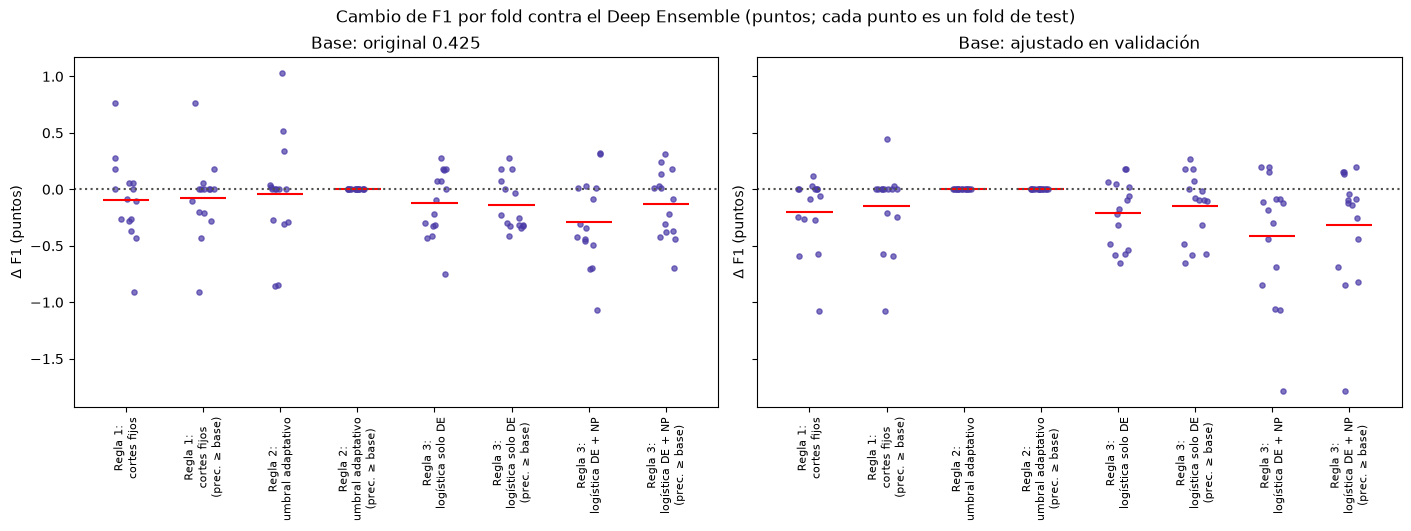

In [7]:
rules = [r for r in scores['regla'].unique() if r != 'Deep Ensemble']
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, constrained_layout=True)
fig.suptitle('Cambio de F1 por fold contra el Deep Ensemble (puntos; cada punto es un fold de test)')
for ax, base in zip(axes, scores['base'].unique()):
    part = scores[scores['base'] == base].set_index(['evaluación', 'fold'])
    ref = part[part['regla'] == 'Deep Ensemble']['F1 (%)']
    for i, rule in enumerate(rules):
        delta = part[part['regla'] == rule]['F1 (%)'] - ref
        ax.scatter(np.full(len(delta), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(delta)), delta, s=14, color='#4a3aa7', alpha=0.7)
        ax.hlines(delta.mean(), i - 0.3, i + 0.3, color='red')
    ax.axhline(0, color=report.CHANCE, linestyle=':')
    ax.set_xticks(range(len(rules)), [r.replace(' (precisión ≥ base)', '\n(prec. ≥ base)').replace(': ', ':\n') for r in rules],
                  rotation=90, fontsize=8)
    ax.set_title(f'Base: {base}')
    ax.set_ylabel('Δ F1 (puntos)')
show(fig)

### Validación vs test

Para ver si las reglas no funcionan o si lo que ganan en validación no se mantiene en test: F1 de la regla logística DE + NP en validación (los mismos datos con que se eligió) frente a test.

In [8]:
rows = []
for evaluation in report.EVALUATIONS:
    for fold in report.FOLDS:
        val = ht.load_pair(evaluation, fold, 'validation')
        val_events = ht.event_table(val, ht.DURATION_THRESHOLD)
        fitted = ht.rule_logistic(val_events, ht.DE_FEATURES + ht.NP_FEATURES, None)
        base = ht.event_scores(val['y_true'], ht.process_masks(val['de']['probability'], ht.DURATION_THRESHOLD))['F1 (%)']
        rule = ht.event_scores(val['y_true'], ht.edited_masks(val['y_true'].shape, val_events, ht.apply_logistic(val_events, fitted)))['F1 (%)']
        test = scores[(scores['base'] == 'original 0.425') & (scores['evaluación'] == evaluation) & (scores['fold'] == fold)].set_index('regla')['F1 (%)']
        rows.append({'evaluación': evaluation, 'fold': fold, 'Δ F1 validación': rule - base,
                     'Δ F1 test': test['Regla 3: logística DE + NP'] - test['Deep Ensemble']})
in_sample = pd.DataFrame(rows)
display(report.by_evaluation(in_sample, ['Δ F1 validación', 'Δ F1 test']))

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
Δ F1 validación,0.7201 ± 0.31,0.8888 ± 0.36,0.697 ± 0.39,0.7686 ± 0.34
Δ F1 test,-0.2271 ± 0.41,-0.4096 ± 0.23,-0.2324 ± 0.54,-0.2897 ± 0.39


### Parámetros elegidos

Mediana entre folds de los cortes elegidos en validación (base original). `inf` en τ significa que la regla prefirió no borrar o no agregar nada.

In [9]:
chosen = params[params['base'] == 'original 0.425']
keys = [c for c in chosen.columns if c.startswith(('regla', 'umbral'))]
display(chosen[keys].replace(np.inf, np.nan).median().to_frame('mediana').round(3))
print('Folds donde la regla 1 no borra nada:', int(np.isinf(chosen['regla 1: tau_fp']).sum()), '/ 15;',
      'no agrega nada:', int(np.isinf(chosen['regla 1: tau_fn']).sum()), '/ 15')

,mediana
umbral DE,0.425
regla 1: t_p,0.550
regla 1: tau_fp,0.329
regla 1: tau_fn,0.506
regla 1 (precisión ≥ base): t_p,0.550
regla 1 (precisión ≥ base): tau_fp,0.424
regla 1 (precisión ≥ base): tau_fn,0.534
regla 2: beta,0.050
regla 2 (precisión ≥ base): beta,0.000
regla 3 solo DE: corte detecciones,0.360


Folds donde la regla 1 no borra nada: 8 / 15; no agrega nada: 2 / 15


## 6. Corregir un solo tipo de error

Las mismas reglas, pero cada una hace **una sola cosa**: o solo borra detecciones (FP), o solo agrega casi detectados (FN). Tienen menos parámetros que las reglas combinadas, así que se sobreajustan menos a validación. Base: umbral original 0.425.

In [10]:
single = ht.run_single(refresh=REFRESH)
display(ht.summary(single).droplevel(0))

,F1 (%),precisión (%),recall (%),FP,FN,Δ F1 (puntos),Δ precisión (puntos),folds que mejoran F1,p Wilcoxon
regla,,,,,,,,,
Deep Ensemble,83.57 ± 0.85,84.38 ± 3.25,82.98 ± 3.18,166.9,181.8,0.00,0.00,0/15,NaN
Solo FP: cortes fijos (MI de NP),83.58 ± 0.96,85.61 ± 3.17,81.83 ± 3.13,149.7,193.9,0.01,1.23,4/15,0.8658
Solo FN: cortes fijos (MI de NP),83.47 ± 0.83,83.20 ± 3.24,83.96 ± 3.28,183.9,171.3,-0.10,-1.18,5/15,0.1330
Solo FP: logística solo DE,83.56 ± 0.94,85.88 ± 3.30,81.57 ± 3.33,146.1,196.8,-0.01,1.50,5/15,0.6002
Solo FN: logística solo DE,83.46 ± 0.89,82.80 ± 3.58,84.40 ± 3.55,190.7,166.8,-0.11,-1.59,6/15,0.2078
Solo FP: logística DE + NP,83.52 ± 0.94,85.90 ± 3.61,81.54 ± 3.68,146.3,197.2,-0.04,1.51,4/15,0.3882
Solo FN: logística DE + NP,83.32 ± 1.00,82.36 ± 3.89,84.63 ± 3.78,197.7,164.3,-0.24,-2.02,5/15,0.0554


**Resultado.** Ninguna sube el F1, pero funcionan como un control: **solo FP** sube la precisión hasta +1.5 puntos (logística del Deep Ensemble, 85.9%) con el F1 igual, y **solo FN** sube el recall hasta +1.65 (84.6%) con el F1 algo menor. Por cada huso recuperado entran casi dos FP nuevos. La MI de Neural Process no mejora la versión con solo el Deep Ensemble.

## Hallazgos

Promedio de los 15 folds de test.

1. **Ajustar el umbral de probabilidad casi no cambia nada.** Deep Ensemble 83.57 → 83.59, SEED 82.72 → 82.88, Neural Process 83.34 → 83.14. El umbral original ya está cerca del óptimo, porque la probabilidad está bien calibrada.
2. **En las detecciones, la MI de Neural Process repite lo que ya dice la probabilidad del Deep Ensemble.** Separa los FP con AUROC 0.83, pero la probabilidad del Deep Ensemble sola llega a 0.86, y juntarlas en la logística da 0.861 contra 0.859 (+0.002, lejos del +0.02 exigido). Las MI de los dos métodos están muy correlacionadas en esos eventos (ρ ≈ 0.73).
3. **En los casi detectados, ninguna medida sirve.** La MI de Neural Process baja de AUROC 0.71 (medida sobre el tramo real del huso, notebooks 06 y 07) a ~0.55 sobre los tramos que el modelo realmente ve. Solo ~35% de esos tramos son husos reales, menos que el 42% necesario para que agregar suba el F1, y nada permite elegir un subconjunto mejor.
4. **Solo un tercio de los husos perdidos está entre los casi detectados.** El resto tiene probabilidad < 0.25: ninguna regla basada en estos tramos puede recuperarlos.
5. **Ninguna regla mejora el F1 en test.** Los cambios van de 0 a −0.4 puntos. La logística DE + NP sube el F1 +0.77 puntos en validación, pero baja −0.29 en test: lo que gana es sobreajuste a los datos con que se eligió. Los cortes elegidos para agregar casi detectados quedan en ~0.42, justo el F1/2 que predice la teoría, pero casi ningún tramo lo supera en test.
6. **Lo que sí se puede hacer es cambiar F1 por precisión.** Las versiones *(precisión ≥ base)* suben la precisión ~0.5–0.7 puntos con una pérdida de F1 de ~0.1. Es útil si un FP cuesta más que un FN.

**Conclusión.** Mezclar los dos métodos con un umbral no mejora la detección de SEED. La incertidumbre de los dos métodos sigue sirviendo para **señalar** detecciones dudosas y mandarlas a revisión (notebook 07, sección 8: el 20% más incierto contiene ~60% de los FP), pero no para **decidir** automáticamente mejor que la probabilidad del Deep Ensemble. Para recuperar husos perdidos haría falta una señal que aparezca donde la probabilidad es baja; en estos datos, la MI no la da.